<a href="https://colab.research.google.com/github/WAppo31/repos/blob/main/CNN_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook, we will be creating a CNN (Convolutional Neural Network) based classifier for the classification of CIFAR-10 dataset.

**About the dataset**

CIFAR-10 dataset is a subset of CIFAR-100 having 80 million images of 100 different objects. CIFAR-10 takes 60,000 images for 10 classes from the original dataset in which 50,000 images are for training and 10,000 images are for testing.

The classes in the dataset are -
* airplane
* automobile
* bird
* cat
* deer
* dog
* frog
* horse
* ship
* truck

In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 698s 4us/step


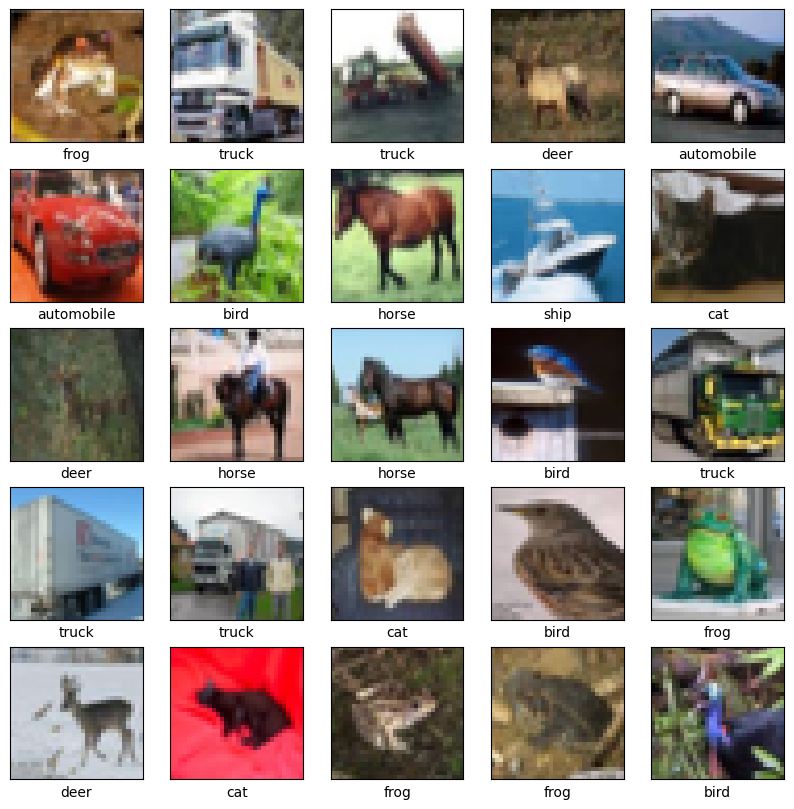

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

**Creating a CNN model**

We are going to create a CNN based classification model using *keras* module.

In [ ]:
model = models.Sequential()

model.add(layers.Conv2D(32,(3,3),activation='relu', input_shape=(32,32,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='sgd',loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=10,validation_data=(test_images, test_labels))


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 47s 30ms/step - accuracy: 0.2457 - loss: 2.0465 - val_accuracy: 0.3225 - val_loss: 1.9066
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 27ms/step - accuracy: 0.3894 - loss: 1.6848 - val_accuracy: 0.4139 - val_loss: 1.6168
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 43s 27ms/step - accuracy: 0.4637 - loss: 1.4910 - val_accuracy: 0.4876 - val_loss: 1.3979
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.5126 - loss: 1.3656 - val_accuracy: 0.5312 - val_loss: 1.3066
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 85s 29ms/step - accuracy: 0.5459 - loss: 1.2787 - val_accuracy: 0.5594 - val_loss: 1.2335
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 43s 27ms/step - accuracy: 0.5732 - loss: 1.2064 - val_accuracy: 0.5741 - val_loss: 1.2038
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 88s 32ms/step - accuracy: 0.5974 - loss: 1.1423 - val_accuracy: 0.5959 - val_loss: 1.1437
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 28ms/step - accuracy: 0.6207 -

313/313 - 2s - 8ms/step - accuracy: 0.6442 - loss: 1.0131


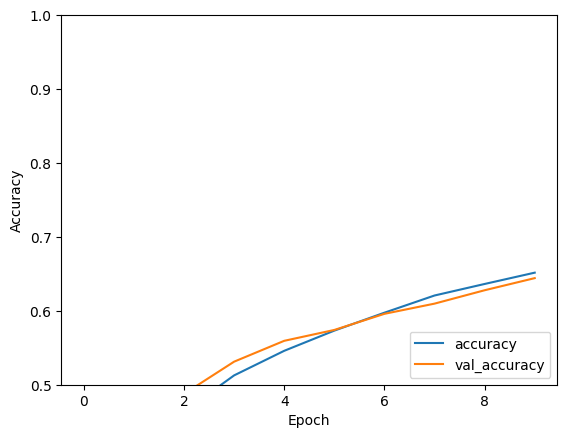

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [ ]:
print(test_acc)

0.7021999955177307


In [ ]:
model.compile(optimizer='adam',loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=10,validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 27ms/step - accuracy: 0.6319 - loss: 1.0465 - val_accuracy: 0.6350 - val_loss: 1.0323
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.6838 - loss: 0.9046 - val_accuracy: 0.6706 - val_loss: 0.9654
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.7220 - loss: 0.7934 - val_accuracy: 0.6879 - val_loss: 0.9193
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 45s 29ms/step - accuracy: 0.7521 - loss: 0.7080 - val_accuracy: 0.6874 - val_loss: 0.9167
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.7780 - loss: 0.6352 - val_accuracy: 0.7147 - val_loss: 0.8535
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.8032 - loss: 0.5667 - val_accuracy: 0.7117 - val_loss: 0.8767
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 42s 27ms/step - accuracy: 0.8195 - loss: 0.5127 - val_accuracy: 0.6976 - val_loss: 0.9271
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 26ms/step - accuracy: 0.8416 -

313/313 - 3s - 10ms/step - accuracy: 0.7132 - loss: 1.0498


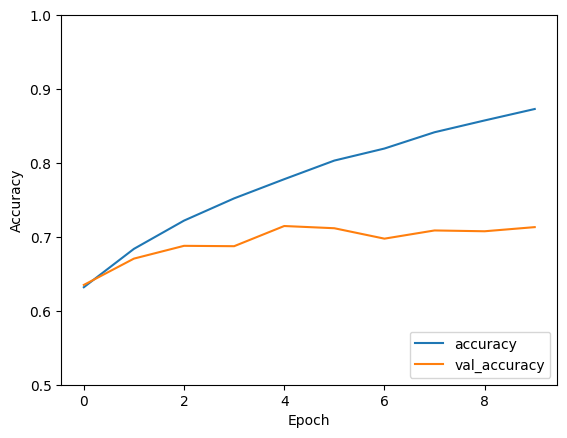

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [ ]:
print(test_acc)

0.7021999955177307


In [ ]:
# save model
model.save('final_model.keras') #previously saved as 'final_model.h5", a legacy

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


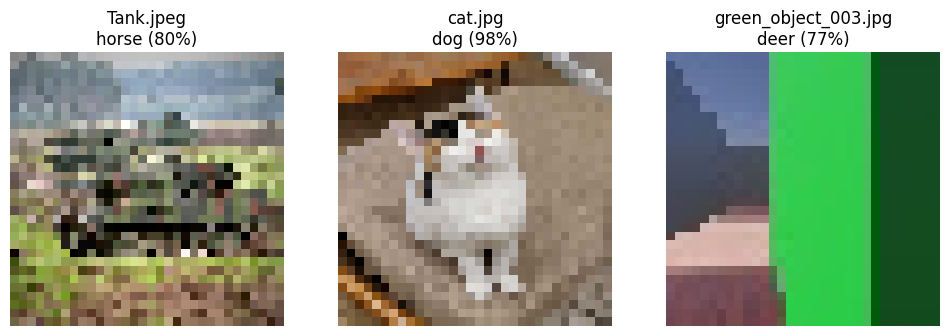

In [18]:
# make a prediction for a new image.
from tensorflow.keras import preprocessing, models
import numpy as np

# define CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# load and prepare the image
def load_image(filename):
	# load the image
	img = preprocessing.image.load_img(filename, target_size=(32, 32))
	# convert to array
	img = preprocessing.image.img_to_array(img)
	# reshape into a single sample with 3 channels
	img = img.reshape(1, 32, 32, 3)
	# prepare pixel data
	img = img.astype('float32')
	img = img / 255.0
	return img

# load an image and predict the class
files = ['Tank.jpeg', 'cat.jpg', 'green_object_003.jpg']
model = models.load_model('final_model.keras')

plt.figure(figsize=(12, 4))
for i, f in enumerate(files):
    img = load_image(f)
    probs = tf.nn.softmax(model.predict(img)[0]).numpy()
    result = np.argmax(probs)

    plt.subplot(1, 3, i+1)
    plt.imshow(img[0])
    plt.axis('off')
    plt.title(f"{f}\n{class_names[result]} ({probs[result]:.0%})")
plt.show()

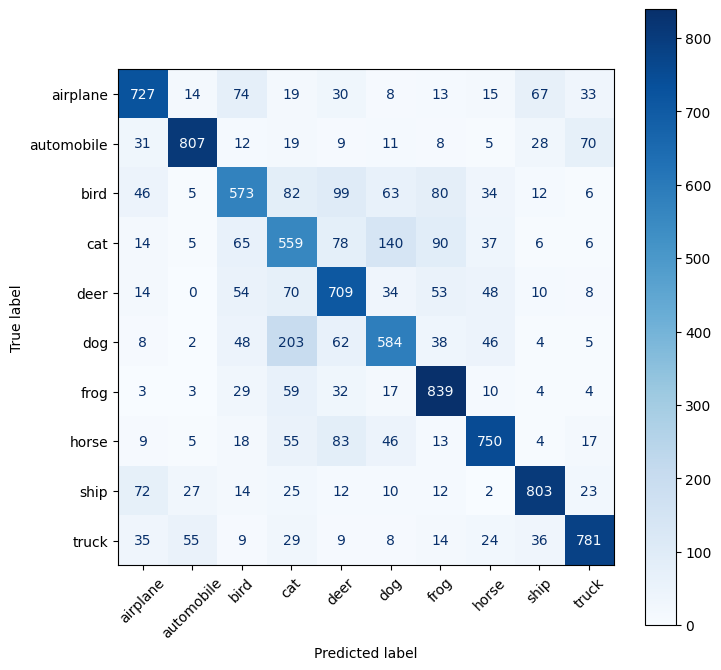

airplane: 72.7%
automobile: 80.7%
bird: 57.3%
cat: 55.9%
deer: 70.9%
dog: 58.4%
frog: 83.9%
horse: 75.0%
ship: 80.3%
truck: 78.1%


In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# predict on all 10,000 test images
pred_probs = model.predict(test_images, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)
y_true = test_labels.flatten()

# confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap='Blues')
plt.show()

# per-class accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for name, acc in zip(class_names, per_class_acc):
    print(f"{name}: {acc:.1%}")

In [20]:
import time, os

# 1. Convert to quantised TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
open('model_quant.tflite', 'wb').write(tflite_model)

interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp = interp.get_input_details()[0]['index']
out = interp.get_output_details()[0]['index']

def tflite_predict(x):
    interp.set_tensor(inp, x.astype('float32'))
    interp.invoke()
    return interp.get_tensor(out)

# 2. Size
orig_kb = os.path.getsize('final_model.keras') / 1024
quant_kb = len(tflite_model) / 1024

# 3. Accuracy on first 1000 test images
n = 1000
orig_acc = np.mean(np.argmax(model.predict(test_images[:n], verbose=0), axis=1) == test_labels[:n].flatten())
quant_acc = np.mean([np.argmax(tflite_predict(test_images[i:i+1])) == test_labels[i][0] for i in range(n)])

# 4. Speed (ms per image)
img = load_image('cat.jpg')
model(img, training=False); tflite_predict(img)   # warm-up
runs = 200

t = time.time()
for _ in range(runs): model(img, training=False)
orig_ms = (time.time() - t) / runs * 1000

t = time.time()
for _ in range(runs): tflite_predict(img)
quant_ms = (time.time() - t) / runs * 1000

print(f"Size:     {orig_kb:.0f} KB -> {quant_kb:.0f} KB")
print(f"Accuracy: {orig_acc:.2%} -> {quant_acc:.2%}")
print(f"Speed:    {orig_ms:.1f} ms -> {quant_ms:.1f} ms ({1000/orig_ms:.0f} -> {1000/quant_ms:.0f} FPS)")

Saved artifact at '/tmp/tmpbdv74xt1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  133451139004176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451138995728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451138995536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139000720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451138996880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139001104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139000912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139004368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139003984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133451139001296: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Size:     1478 KB -> 132 KB
Accuracy: 71.50% -> 71.60%
Speed:    20.1 ms -> 0.3 ms (50 -> 3092 FPS)
